In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline
sys.path.append("../")

import warnings

warnings.filterwarnings("ignore")

Dataset com dados de transações e marcações de fraude de um período de dois anos (2019 e 2020) com dados de 
* lojistas ("store_name" como identificador e segmentação do CNPJ "vertical")
* clientes (data de nascimento, profissão, cidade e estado, **não há coluna identificadora para cliente**)
* transação (valor da transação, dispositivo, bandeira do cartão)
* geolocalização do lojista e do comprador

# OBJETIVO DO CASE
Criar um score de risco por transação, com base nos dados apresentados, considerando os impactos financeiros de cada decisão, apresentados na proposta do case, a saber:
* Falso Negativo (FN - Fraude Não Detectada): A transação é aprovada, mas era fraude. Custo = 100% do amount + Taxa Operacional de Chargeback (ex: R$ 15,00).
* Falso Positivo (FP - Cliente Legítimo Rejeitado): A transação legítima é bloqueada. Custo = Margem Financeira Perdida (ex: 10% do amount) + Custo Operacional de Análise Manual.
* Verdadeiro Positivo (TP - Fraude Bloqueada): Fraude evitada com sucesso.
* Verdadeiro Negativo (TN - Venda Legítima Aprovada): Receita gerada com sucesso.


In [2]:
raw = pd.read_csv('../data/nuvem_fraud_dataset.csv', delimiter=';')
raw.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,"107,23",Mobile,Master Card,Orient,WA,48|8878,-118|2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49|159047,-118|186462,0
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,"220,11",Mobile,Amex,Malad City,ID,42|1808,-112|262,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43|150704,-112|154481,0
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,"96,29",Mobile,Amex,Grenada,CA,41|6125,-122|5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41|65752,-122|230347,0
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,"7,77",Mobile,Visa,High Rolls Mountain Park,NM,32|9396,-105|8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32|863258,-106|520205,0
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,"6,85",Web,Master Card,Freedom,WY,43|0172,-111|0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43|753735,-111|454923,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 341519 entries, 0 to 341518
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   created_at       341519 non-null  str  
 1   store_name       341519 non-null  str  
 2   vertical         341519 non-null  str  
 3   amount           341519 non-null  str  
 4   device           341519 non-null  str  
 5   card_brand       341519 non-null  str  
 6   city             341519 non-null  str  
 7   state            340576 non-null  str  
 8   lat              341308 non-null  str  
 9   long             341197 non-null  str  
 10  city_population  341519 non-null  int64
 11  job              341519 non-null  str  
 12  date_of_birth    341519 non-null  str  
 13  store_lat        341519 non-null  str  
 14  store_long       341519 non-null  str  
 15  is_fraud         341519 non-null  int64
dtypes: int64(2), str(14)
memory usage: 41.7 MB


In [4]:
n_duplicates = raw.duplicated().sum()
print (f"foram encontradas {n_duplicates} entradas duplicadas no dataset")
raw = raw.drop_duplicates()

foram encontradas 1912 entradas duplicadas no dataset


Observou-se a presença de entradas duplicadas na base fornecida (cerca de 0,5 % das observações). Foram removidas antes de iniciar as análises posteriores.

Notou-se também a ausência de alguns valores relacionados ao cliente que realizou transação, relacionados ao estado cadastrado e à geolocalização do mesmo. 

A partir da data dos eventos (transações), cria-se as colunas cohort("safra") e do dia a partir da coluna "created_at". essas informações serão usadas posteriormente para investigações exploratórias e na segmentação das observações para modelagem.

Também são feitos os tratamentos devidos para as colunas numéricas de amount e das coordenadas geográficas

In [5]:
raw['amount'] = pd.to_numeric(raw["amount"].astype(str).str.replace(",", ".", regex=False))
raw['created_at'] = pd.to_datetime(raw["created_at"])

raw["cohort"] = raw["created_at"].dt.to_period('M')
raw["day"] = raw["created_at"].dt.to_period('D')

raw['date_of_birth'] = pd.to_datetime(raw["date_of_birth"])

for col in ['lat', 'long', 'store_lat', 'store_long']:
    raw[col] = raw[col].str.replace('|', '.').astype(float)

Além desses campos, cria-se um id único para cada transação, a partir do dataset ordenado.

In [6]:

raw = raw.reset_index(drop=True)
raw["row_orig"] = raw.index
raw = raw.sort_values(["created_at", "row_orig"]).reset_index(drop=True).drop(["row_orig"], axis=1)
raw["txn_id"] = raw.index
raw.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud,cohort,day,txn_id
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,107.23,Mobile,Master Card,Orient,WA,48.8878,-118.2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49.159047,-118.186462,0,2019-01,2019-01-01,0
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,220.11,Mobile,Amex,Malad City,ID,42.1808,-112.2620,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43.150704,-112.154481,0,2019-01,2019-01-01,1
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,96.29,Mobile,Amex,Grenada,CA,41.6125,-122.5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41.657520,-122.230347,0,2019-01,2019-01-01,2
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,7.77,Mobile,Visa,High Rolls Mountain Park,NM,32.9396,-105.8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32.863258,-106.520205,0,2019-01,2019-01-01,3
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,6.85,Web,Master Card,Freedom,WY,43.0172,-111.0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43.753735,-111.454923,0,2019-01,2019-01-01,4


Nota-se que há um pequeno volume de transações (menos de 0.1% da base) sem informações de geolocalização do cliente. Essas transações se concentraram em dias específicos do período de observação e nenhuma delas foi observada como fraude 


In [7]:
sem_coordenadas = raw[raw[["lat", "long"]].isna().any(axis=1)]

sem_coordenadas.groupby("day")["is_fraud"].agg(["mean", "count"])

,mean,count
day,,
2019-03-29,0.0,31
2019-09-25,0.0,29
2020-02-11,0.0,17
2020-05-30,0.0,260
2020-09-04,0.0,147
2020-12-21,0.0,16


Um padrão mais interessante foi observado para casos em que o campo "state" estava ausente, embora também aparece em dias específicos, quando ausente, foi observado um volume relevante de fraude/chargeback


In [8]:
sem_estado = raw[raw["state"].isna()]

sem_estado.groupby("day")["is_fraud"].agg(["mean", "count"])

,mean,count
day,,
2019-02-28,0.000000,151
2019-03-01,0.035088,57
2019-09-15,0.000000,35
2019-12-23,0.017995,389
2019-12-24,0.010909,275
2020-12-31,0.000000,36


---

Avaliando o perfil de fraudes (taxa de fraude e perda financeira) ao longo do período observado, npta-se que há uma taxa média de fraude de 0.5% das transações no período, com uma média de perda em US$39 mil dólares/mês.

No início do período observado a perda estava na máxiam histórica e houve uma queda abrupta nas fraudes no final do primeiro semestre, seguida de um leve aumento em agosto de 2019. a mesma oscilação padrão ocorreu entre o final de 2019 e inicio de 2020, provavelmente devido a atualização das políticas de prevenção  seguida de mudança de modus operandi dos fraudadores e ajuste de regras internas.

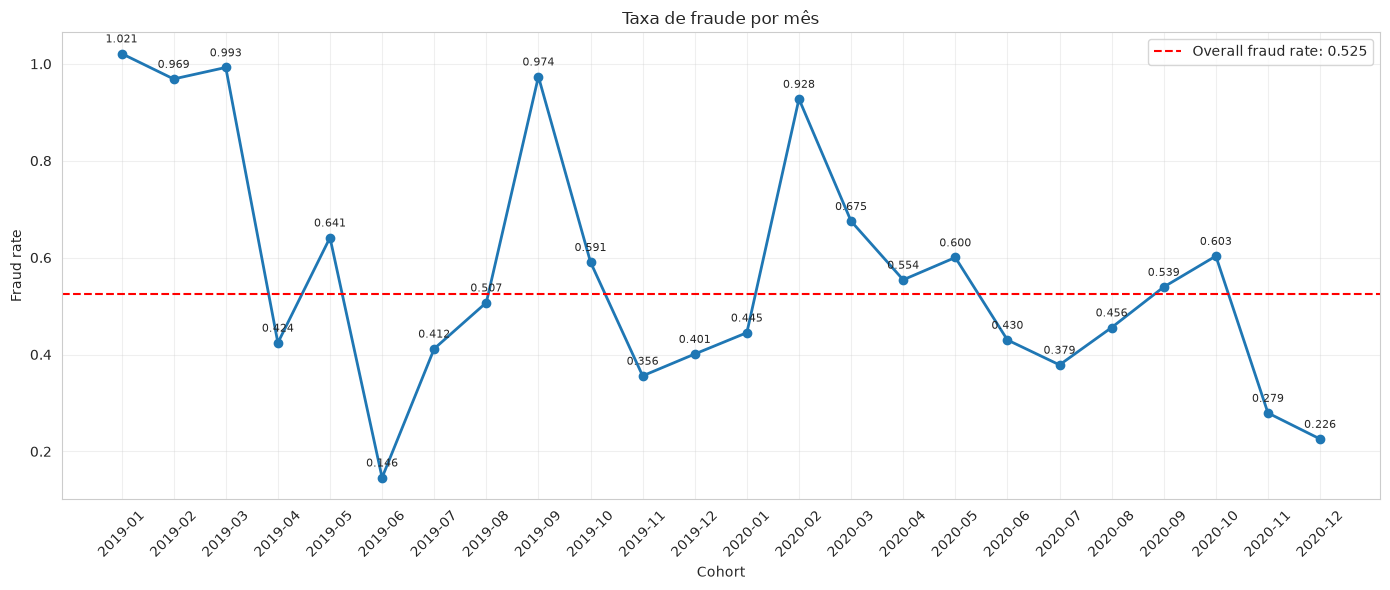

In [9]:
monthly_fraud = raw.groupby("cohort")["is_fraud"].mean().sort_index() * 100
overall_fraud_rate = raw["is_fraud"].mean() * 100

x = monthly_fraud.index.astype(str).tolist()
y = monthly_fraud.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, y, marker="o", linewidth=2)

for i, (month, rate) in enumerate(monthly_fraud.items()):
    ax.annotate(
        f"{rate:.3f}",
        (x[i], float(rate)),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )

ax.set_title("Taxa de fraude por mês")
ax.set_xlabel("Cohort")
ax.set_ylabel("Fraud rate")
ax.axhline(
    overall_fraud_rate,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall fraud rate: {overall_fraud_rate:.3f}",
)
ax.legend(loc="upper right")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

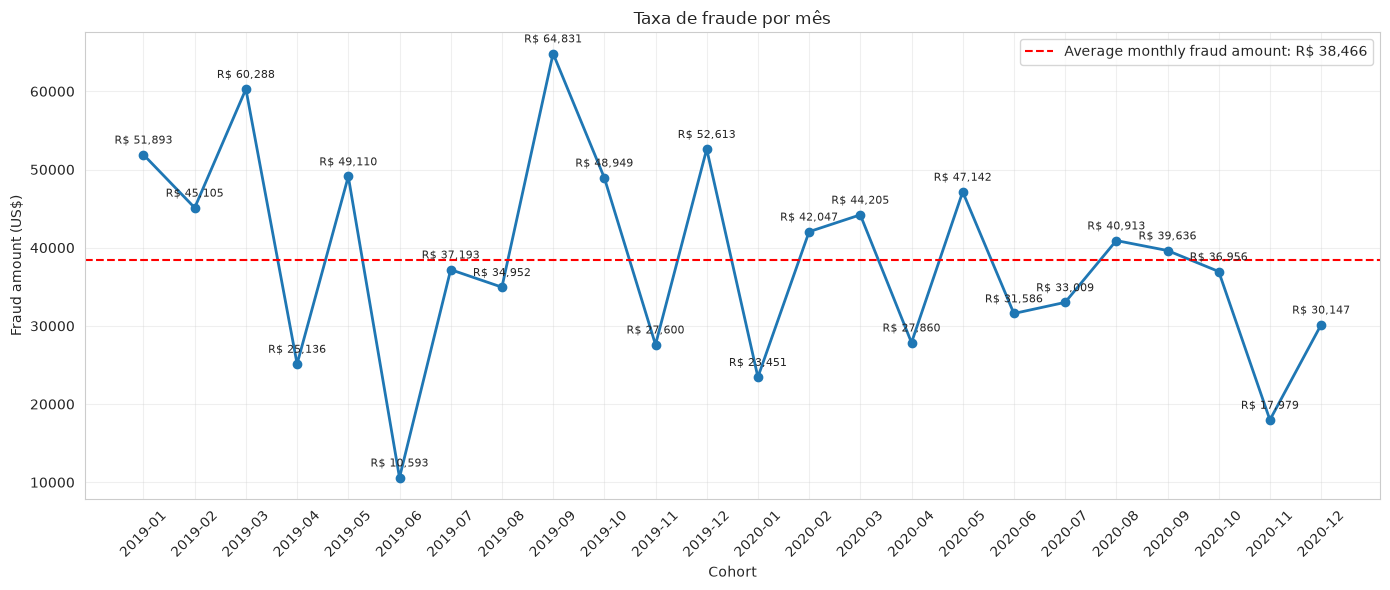

In [10]:
amount_num = pd.to_numeric(
    raw["amount"].astype(str).str.replace(",", ".", regex=False)
)

monthly_fraud_amount = (
    raw.loc[raw["is_fraud"].eq(1)]
    .assign(amount_num=amount_num)
    .groupby("cohort")["amount_num"]
    .sum()
    .reindex(monthly_fraud.index, fill_value=0)
)

average_monthly_fraud_amount = monthly_fraud_amount.mean()
x = monthly_fraud_amount.index.astype(str).tolist()
y = monthly_fraud_amount.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, y, marker="o", linewidth=2)

for i, amount in enumerate(y):
    ax.annotate(
        f"R$ {amount:,.0f}",
        (x[i], amount),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )

ax.set_title("Taxa de fraude por mês")
ax.set_xlabel("Cohort")
ax.set_ylabel("Fraud amount (US$)")
ax.axhline(
    average_monthly_fraud_amount,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Average monthly fraud amount: R$ {average_monthly_fraud_amount:,.0f}",
)
ax.legend(loc="upper right")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

A seguir são apresentadas análises exploratórias a partir das variáveis fornecidas no dataset e sua relação com a variável target. A função definida abaixo, calcula a porcentagem de bads, weight of evidence e information value para variáveis categóricas e é utilizada ao longo de toda a análise.

In [12]:
def iv_woe_category(
    df: pd.DataFrame,
    category: str,
    target: str = "is_fraud",
) -> pd.DataFrame:
    """
    Calcula IV, WoE, fraud rate e lift por categoria.

    Target:
        0 = Não fraude
        1 = Fraude
    """
    aux = (
        df.groupby([category, target], dropna=False)
        .size()
        .unstack(fill_value=0)
        .reindex(columns=[0, 1], fill_value=0)
    )

    aux = aux.rename(columns={
        0: "n_legit",
        1: "n_fraud",
    })

    # Volume e taxa de fraude
    aux["n_txns"] = aux["n_legit"] + aux["n_fraud"]
    aux["pct_population"] = aux["n_txns"] / len(df)

    aux["fraud_rate"] = (
        aux["n_fraud"] / aux["n_txns"]
    )

    base_rate = df[target].mean()

    aux["lift"] = (
        aux["fraud_rate"] / base_rate
        if base_rate > 0 else np.nan
    )

    # Distribuições para WoE / IV
    # Smoothing para evitar log(0)
    eps = 0.5

    n_categories = len(aux)

    dist_fraud = (
        (aux["n_fraud"] + eps)
        / (aux["n_fraud"].sum() + eps * n_categories)
    )

    dist_legit = (
        (aux["n_legit"] + eps)
        / (aux["n_legit"].sum() + eps * n_categories)
    )

    aux["WOE"] = np.log(dist_fraud / dist_legit)

    aux["IV"] = (
        (dist_fraud - dist_legit) * aux["WOE"]
    )

    return aux.sort_values("lift", ascending=False)


---

## Valor Transacionado

Analisando isoladamente o valor de cada transação, nota-se que há uma grande discrepância entre o comportamento de transações legítimas (majoritariamente de baixo valor) de transações fraudulentas.

Cerca de 75 % das transações fraudulentas apresentam valores maiores que US$ 200 doláres. Um corte seco nesse valor,capturaria um volume significativo de transações legítimas coom alto valor, causando impacto e fricção com a base de vendedores.

Observando a descritiva do valor geral

In [13]:
raw['amount'].describe()


count    339607.000000
mean         70.577984
std         161.675242
min           1.000000
25%           9.600000
50%          46.460000
75%          83.350000
max       28948.900000
Name: amount, dtype: float64

Segmentando as transações fraudulentas e legítimas e adicionando alguns percentis na porção superior, notamos um valor atípico e alto de transação legitima, acima de US$ 20000

In [14]:
raw.loc[raw['amount']>20000]

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud,cohort,day,txn_id
144783,2019-12-01 16:19:23+00:00,'Satterfield-Lowe',travel,28948.9,Mobile,Master Card,Westerville,NE,41.4193,-99.3844,73,'Product designer',1935-02-10 00:00:00+00:00,42.317313,-99.139498,0,2019-12,2019-12-01,144783


In [15]:
amount_describe = (
    raw.groupby("is_fraud")["amount"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

amount_describe

,count,mean,std,min,25%,50%,75%,95%,99%,99.5%,99.9%,max
is_fraud,,,,,,,,,,,,
Não fraude,337825.0,68.217523,156.251647,1.00,9.5700,46.250,82.760,193.1460,489.6128,681.08640,1593.11480,28948.90
Fraude,1782.0,518.065460,389.627409,1.78,214.6775,356.435,884.725,1084.5975,1176.2429,1210.14555,1319.12652,1371.81


Simulando a aplicação de uma política simples (classificando operações acima de US$ 200 como fraudulentas), temos uma detecção de cerca de 75% no histórico, mas com um alto impacto financeiro em receita (perda de cerca US$ 6MM em operações legítimas, no acumulado)

In [16]:
raw['high_amount'] = np.where(raw['amount']>200, 1, 0)

In [17]:
pd.crosstab(
    index=raw["high_amount"],
    columns=raw["is_fraud"],
    values=raw["amount"],
    aggfunc="sum",
    margins=True,
    margins_name="Total",
).rename_axis(index="high_amount", columns="is_fraud")

is_fraud,0,1,Total
high_amount,,,
0,16424899.47,11550.03,16436449.5
1,6620685.28,911642.62,7532327.9
Total,23045584.75,923192.65,23968777.4


In [18]:
pd.crosstab(
    index=raw["high_amount"],
    columns=raw["is_fraud"],
    values=raw["txn_id"],
    aggfunc="count",
    margins=True,
    margins_name="Total",
).rename_axis(index="high_amount", columns="is_fraud")

is_fraud,0,1,Total
high_amount,,,
0,322469,444,322913
1,15356,1338,16694
Total,337825,1782,339607


In [19]:
1336/1782

0.7497194163860831

In [20]:
raw['log_amount'] = np.log10(raw['amount'] + 1)

In [21]:
raw['log_amount'].describe()


count    339607.000000
mean          1.531519
std           0.561953
min           0.301030
25%           1.025306
50%           1.676328
75%           1.926085
max           4.461647
Name: log_amount, dtype: float64

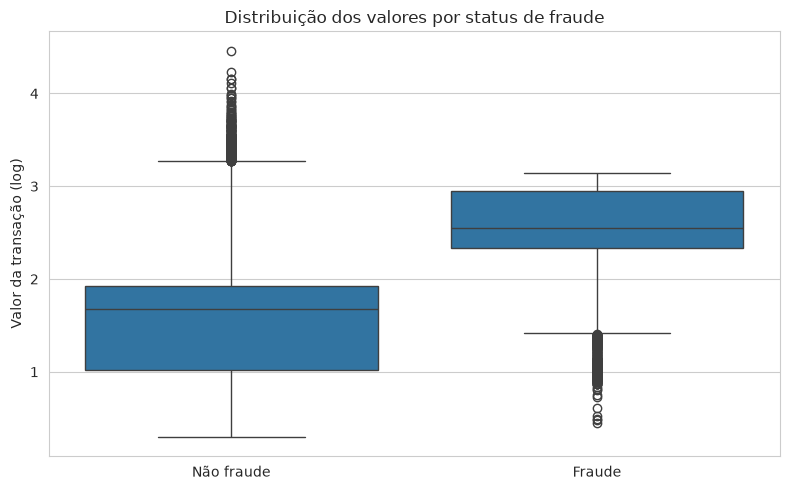

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=raw, x="is_fraud", y="log_amount", ax=ax)
ax.set_xticks([0, 1], ["Não fraude", "Fraude"])
ax.set_xlabel("")
ax.set_ylabel("Valor da transação (log)")
ax.set_title("Distribuição dos valores por status de fraude")

plt.tight_layout()
plt.show()

In [23]:
iv_woe_category(raw, 'high_amount', 'is_fraud')

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
high_amount,,,,,,,,
1,15356,1338,16694,0.049157,0.080149,15.274417,2.804244,1.977677
0,322469,444,322913,0.950843,0.001375,0.262039,-1.342580,0.946847


---

# Vertical


Dentre os 14 grupos de merchants ('vertical'), destacam-se três grupos, sendo:

* Alto Risco (shopping_net, grocery_pos, misc_net)
* Médio Risco (shopping_pos,gas_transport,travel, misc_pos)
* Baixo Risco (outros)


Faz-se a recategorização

In [24]:
iv_woe_category(raw, 'vertical', 'is_fraud')

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
vertical,,,,,,,,
shopping_net,25998,381,26379,0.077675,0.014443,2.752552,1.019209,0.138909
grocery_pos,32299,433,32732,0.096382,0.013229,2.521066,0.929977,0.136433
misc_net,16681,217,16898,0.049758,0.012842,2.447335,0.901035,0.065053
shopping_pos,30142,187,30329,0.089306,0.006166,1.175039,0.160979,0.002509
gas_transport,34936,153,35089,0.103322,0.004360,0.830978,-0.186695,0.003288
travel,10289,33,10322,0.030394,0.003197,0.609283,-0.486442,0.005707
misc_pos,19962,62,20024,0.058962,0.003096,0.590078,-0.525552,0.012694
grocery_net,11328,27,11355,0.033436,0.002378,0.453154,-0.779999,0.014166
entertainment,24167,55,24222,0.071324,0.002271,0.432735,-0.835489,0.033849


In [27]:
vertical_groups = {
    "vertical_high_risk": ["shopping_net", "grocery_pos", "misc_net"],
    "vertical_medium_risk": ["shopping_pos", "gas_transport", "travel", "misc_pos"],
    "vertical_low_risk": [
        "grocery_net", "entertainment", "personal_care", "kids_pets",
        "food_dining", "health_fitness", "home",
    ],
}

vertical_to_group = {
    vertical: group
    for group, verticals in vertical_groups.items()
    for vertical in verticals
}

raw["vertical_group"] = raw["vertical"].map(vertical_to_group)

# Check that every vertical was assigned, then summarize the groups.
assert raw["vertical_group"].notna().all(), "Some verticals were not assigned to a group."

raw.groupby("vertical_group")["is_fraud"].agg(
    transactions="size",
    frauds="sum",
    fraud_rate="mean",
)

,transactions,frauds,fraud_rate
vertical_group,,,
vertical_high_risk,76009,1031,0.013564
vertical_low_risk,167834,316,0.001883
vertical_medium_risk,95764,435,0.004542


In [28]:
iv_woe_category(raw, 'vertical_group', 'is_fraud')

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
vertical_group,,,,,,,,
vertical_high_risk,74978,1031,76009,0.223815,0.013564,2.585012,0.957767,0.341361
vertical_medium_risk,95329,435,95764,0.281985,0.004542,0.865677,-0.144645,0.005497
vertical_low_risk,167518,316,167834,0.494201,0.001883,0.358820,-1.027571,0.327190


# Device

Existem duas categorias de device reportadas ao longo do histórico ('web' e 'mobile') e ambas apresentam baixo poder preditivo isoladamente, com taxas de fraude em torno de 0.5%, conforme o perfil histórico. Não será utilizada para fins da construção do score de risco.

In [29]:
device_iv_woe = iv_woe_category(raw, 'device', 'is_fraud')
device_iv_woe.sort_values('WOE', ascending=False)

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
device,,,,,,,,
Web,112964,604,113568,0.33441,0.005318,1.013561,0.013806,0.000064
Mobile,224861,1178,226039,0.66559,0.005211,0.993187,-0.007009,0.000033


---

# Card Brand

Também não foram notadas diferenças significativas no perfil transacional relacionado às bandeiras ("card brands"). As três apresentadas no dataset (Visa, Mastercard e Amex) apresentam comportamento muito semelhante entre si e próximo a taxa geral de fraude no periodo analisado

In [30]:
bandeira_iv_woe = iv_woe_category(raw, 'card_brand', 'is_fraud')
bandeira_iv_woe.sort_values('WOE', ascending=False)

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
card_brand,,,,,,,,
Master Card,112738,605,113343,0.333748,0.005338,1.017254,0.017183,0.000099
Visa,168636,902,169538,0.499218,0.005320,1.013931,0.013623,0.000093
Amex,56451,275,56726,0.167034,0.004848,0.923888,-0.078595,0.000993


---

# State

Analisando os estados reportados no dataset, vemos que casos em que estado não é preenchido e 'AK' apresentam comportamento distinto e de maior risco quando comparado aos demais, mas ambos são pouco representativos (em torno de 1% da base analisada). 

In [31]:
raw['state'] = raw['state'].fillna('other')
state_iv_woe = iv_woe_category(raw, 'state', 'is_fraud')
state_iv_woe.sort_values('WOE', ascending=False)

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
state,,,,,,,,
AK,2903,50,2953,0.008695,0.016932,3.226826,1.189193,0.023348
other,931,12,943,0.002777,0.012725,2.425149,0.929824,0.003933
OR,26128,197,26325,0.077516,0.007483,1.426155,0.355849,0.011763
NE,34116,216,34332,0.101093,0.006292,1.199012,0.180946,0.003624
CO,19590,115,19705,0.058023,0.005836,1.112219,0.107362,0.000706
NM,23222,121,23343,0.068735,0.005184,0.987865,-0.012071,0.000010
CA,79883,402,80285,0.236406,0.005007,0.954246,-0.049738,0.000571
WA,26835,126,26961,0.079389,0.004673,0.890643,-0.116347,0.001015
MO,54514,253,54767,0.161266,0.004620,0.880381,-0.129966,0.002556


In [32]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 339607 entries, 0 to 339606
Data columns (total 22 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   created_at       339607 non-null  datetime64[us, UTC]
 1   store_name       339607 non-null  str                
 2   vertical         339607 non-null  str                
 3   amount           339607 non-null  float64            
 4   device           339607 non-null  str                
 5   card_brand       339607 non-null  str                
 6   city             339607 non-null  str                
 7   state            339607 non-null  str                
 8   lat              339396 non-null  float64            
 9   long             339285 non-null  float64            
 10  city_population  339607 non-null  int64              
 11  job              339607 non-null  str                
 12  date_of_birth    339607 non-null  datetime64[us, UTC]
 13  store_lat 

# Age



In [33]:
raw["age"] = (
    raw["created_at"].dt.year
    - raw["date_of_birth"].dt.year
    - (
        (raw["created_at"].dt.month < raw["date_of_birth"].dt.month)
        | (
            (raw["created_at"].dt.month == raw["date_of_birth"].dt.month)
            & (raw["created_at"].dt.day < raw["date_of_birth"].dt.day)
        )
    ).astype(int)
)

In [34]:
age_describe = (
    raw.groupby("is_fraud")["age"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

age_describe

,count,mean,std,min,25%,50%,75%,95%,99%,99.5%,99.9%,max
is_fraud,,,,,,,,,,,,
Não fraude,337825.0,47.281968,17.014444,17.0,34.0,45.0,58.0,83.0,91.0,92.0,93.0,93.0
Fraude,1782.0,50.241863,18.312141,19.0,35.0,50.0,63.0,83.0,91.0,91.0,91.0,91.0


In [728]:
raw.groupby("age")["is_fraud"].agg(
    n_txns="count",
    n_frauds="sum",
    fraud_rate="mean"
).sort_values(by='fraud_rate', ascending=False).head(10)

,n_txns,n_frauds,fraud_rate
age,,,
87,368,15,0.040761
22,1375,53,0.038545
89,365,12,0.032877
77,1443,36,0.024948
73,1108,21,0.018953
50,3025,42,0.013884
23,1768,24,0.013575
64,4686,59,0.012591
62,3777,46,0.012179


---

In [729]:
# Distancia Cliente - Lojista

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0

    lat1, lon1, lat2, lon2 = map(
        np.radians, (lat1, lon1, lat2, lon2)
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

raw["distance_km"] = haversine(
    raw["lat"],
    raw["long"],
    raw["store_lat"],
    raw["store_long"]
)

In [730]:
distance_describe = (
    raw.groupby("is_fraud")["distance_km"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

distance_describe

,count,mean,std,min,25%,50%,75%,95%,99%,99.5%,99.9%,max
is_fraud,,,,,,,,,,,,
Não fraude,337325.0,75.575632,29.057432,0.205072,54.725475,77.614035,97.951126,119.894983,131.258064,134.254957,138.788536,152.117173
Fraude,1782.0,75.573043,28.483529,1.449529,55.755169,77.364438,96.948835,118.558580,131.830803,135.682310,140.166512,142.484909


---

# Resolução de Identidades

De modo a se obter informação para **cada cliente**, como fator importante para construção do score antifraude e pelo fato de **não possuir um identificador único do dataset**, para esse caso, assumo a construção de um **identificador proxy**, baseado nos dados fornecidos no dataset (data de nascimento, profissão e cidade). Desse modo, foram identificados, **187 clientes únicos** operando em **700** lojistas identificados 

Com esse identificador construído, será possível construir variáveis transacionais com base na movimentação do cliente.

Para implantação em produção do modelo, deverá ser considerada a construção de features baseadas em customer_id e store_id próprios.

In [731]:
raw["customer_id"] = raw.groupby(
    ["date_of_birth", "job", "city"],
    dropna=False
).ngroup()

raw['customer_id'].nunique()

187

In [770]:
customer_fraud_labels = (
    raw.groupby("customer_id")
    .agg(
        n_transactions=("txn_id", "count"),
        n_fraud_transactions=("is_fraud", "sum"),
    )
    .reset_index()
)

customer_fraud_labels["fraud_transaction_pct"] = (
    100 * customer_fraud_labels["n_fraud_transactions"]
    / customer_fraud_labels["n_transactions"]
)



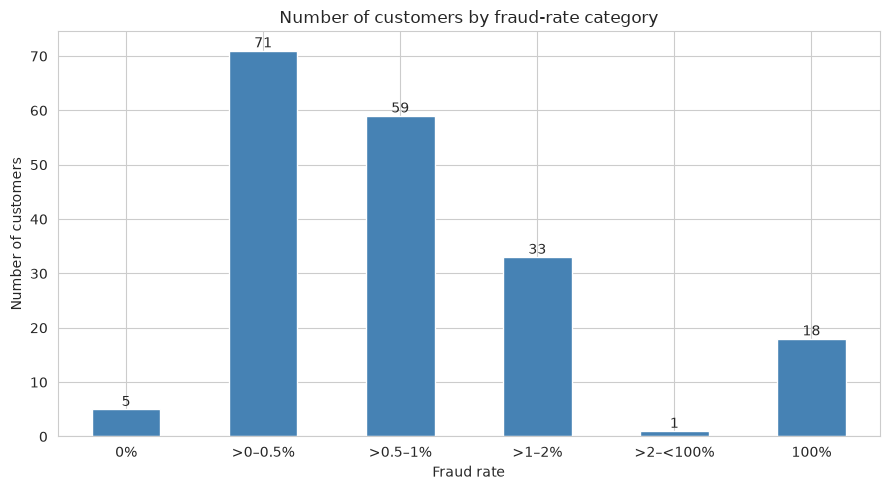

In [769]:
fraud_pct = customer_fraud_labels["fraud_transaction_pct"]

bins = [
    "0%",
    ">0–0.5%",
    ">0.5–1%",
    ">1–2%",
    ">2–<100%",
    "100%",
]

conditions = [
    fraud_pct.eq(0),
    fraud_pct.gt(0) & fraud_pct.le(0.5),
    fraud_pct.gt(0.5) & fraud_pct.le(1),
    fraud_pct.gt(1) & fraud_pct.le(2),
    fraud_pct.gt(2) & fraud_pct.lt(100),
    fraud_pct.eq(100),
]

customer_bins = pd.Series(
    np.select(conditions, bins, default="Other"),
    index=customer_fraud_labels.index,
)

counts = customer_bins.value_counts().reindex(bins, fill_value=0)

ax = counts.plot(kind="bar", figsize=(9, 5), color="steelblue")
ax.set_title("Number of customers by fraud-rate category")
ax.set_xlabel("Fraud rate")
ax.set_ylabel("Number of customers")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Observa-se que para lojas, existem 7 casos onde o mesmo store_name apresenta mais de um "vertical". Assumiu-se que a são canais distintos para o mesmo vendedor (físico e online), **de modo que passei a usar a chave composta para construção do store_id**

In [732]:
inconsistent_stores = (
    raw.groupby(["store_name", "vertical"], dropna=False)
    .size()
    .rename("row_count")
    .reset_index()
    .groupby("store_name")["vertical"]
    .nunique()
    .loc[lambda s: s > 1]
    .index
)

pair_counts = (
    raw.groupby(["store_name", "vertical"], dropna=False)
    .size()
    .rename("row_count")
    .reset_index()
)

pair_counts[pair_counts["store_name"].isin(inconsistent_stores)] \
    .sort_values(["store_name", "vertical"])

,store_name,vertical,row_count
70,'Boyer PLC',misc_pos,370
71,'Boyer PLC',shopping_net,499
106,'Cormier LLC',health_fitness,464
107,'Cormier LLC',shopping_net,521
138,'Dickinson Lt',misc_pos,407
139,'Dickinson Lt',personal_care,484
194,'Gislason Group',misc_pos,440
195,'Gislason Group',travel,211
320,'Kilback LLC',food_dining,441
321,'Kilback LLC',grocery_pos,708


In [733]:
raw["store_id"] = raw.groupby(
    ["store_name", "vertical"],
    dropna=False
).ngroup()

raw['store_id'].nunique()

700

Um ponto de atenção notável com relação às informações das lojas, foi a variação entre store_lat e store_long dentro de cada store_id, sinalizando que as coordenadas apresentadas **não representam a localização do ponto de venda físico/online de forma confiável** . Desse modo, não será utilizado no desenvolvimento da estratégia analítica esse dado, mas para uma versão produtiva desse case, seria interessante incorporar features de IP e geolocalização do cliente  e match com os dados do cliente.

In [734]:
raw.loc[raw['store_id']==1].head(10)

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,...,cohort,day,txn_id,high_amount,log_amount,vertical_group,age,distance_km,customer_id,store_id
288,2019-01-01 15:47:50+00:00,'Abbott-Steube',personal_care,111.13,Mobile,Visa,Roseland,NE,40.4591,-98.5551,...,2019-01,2019-01-01,288,0,2.049722,vertical_low_risk,70,26.225520,25,1
1193,2019-01-04 23:13:03+00:00,'Abbott-Steube',personal_care,100.33,Web,Visa,Carlotta,CA,40.5070,-123.9743,...,2019-01,2019-01-04,1193,0,2.005738,vertical_low_risk,67,133.219727,29,1
1706,2019-01-06 15:11:16+00:00,'Abbott-Steube',personal_care,44.88,Mobile,Visa,Issaquah,WA,47.4974,-122.0107,...,2019-01,2019-01-06,1706,0,1.661623,vertical_low_risk,34,43.193917,139,1
2693,2019-01-08 23:51:33+00:00,'Abbott-Steube',personal_care,60.74,Mobile,Visa,Manley,NE,40.9207,-96.1680,...,2019-01,2019-01-08,2693,0,1.790567,vertical_low_risk,51,62.632228,84,1
2834,2019-01-09 16:45:34+00:00,'Abbott-Steube',personal_care,83.75,Web,Visa,Jordan Valley,OR,42.8801,-117.2810,...,2019-01,2019-01-09,2834,0,1.928140,vertical_low_risk,25,106.729239,173,1
3660,2019-01-12 21:36:58+00:00,'Abbott-Steube',personal_care,177.46,Mobile,Master Card,American Fork,UT,40.3928,-111.7941,...,2019-01,2019-01-12,3660,0,2.251541,vertical_low_risk,26,126.725590,171,1
3873,2019-01-13 14:20:09+00:00,'Abbott-Steube',personal_care,101.74,Mobile,Visa,Sun City,CA,33.7467,-117.1721,...,2019-01,2019-01-13,3873,0,2.011740,vertical_low_risk,46,44.657643,100,1
5210,2019-01-17 12:07:30+00:00,'Abbott-Steube',personal_care,38.78,Mobile,Visa,North Loup,NE,41.4972,-98.7858,...,2019-01,2019-01-17,5210,0,1.599665,vertical_low_risk,38,49.075892,129,1
5839,2019-01-19 23:36:13+00:00,'Abbott-Steube',personal_care,35.92,Mobile,Amex,Mendon,UT,41.7100,-111.9817,...,2019-01,2019-01-19,5839,0,1.567262,vertical_low_risk,55,113.234608,67,1
6012,2019-01-20 13:20:55+00:00,'Abbott-Steube',personal_care,38.53,Web,Amex,Meredith,CO,39.3199,-106.6596,...,2019-01,2019-01-20,6012,0,1.596927,vertical_low_risk,79,79.252811,13,1


---

In [735]:

def add_velocity_features(
    df: pd.DataFrame,
    entity_col: str = "customer_id",
    time_col: str = "created_at",
    windows: tuple[str, ...] = (
        "5min", "15min", "30min", "1h", "6h", "24h"
    ),
) -> pd.DataFrame:
    """
    Calcula features de velocidade transacional por entidade.

    Features:
        - minutes_since_prev_txn
        - txns_prev_5min
        - txns_prev_15min
        - txns_prev_30min
        - txns_prev_1h
        - txns_prev_6h
        - txns_prev_24h

    Considera apenas transações com timestamp estritamente
    anterior ao da transação atual.

    Janelas: [timestamp - janela, timestamp)
    """
    result = df.copy()

    if not result.index.is_unique:
        raise ValueError("O DataFrame deve ter índice único.")

    if result[entity_col].isna().any():
        raise ValueError(f"Existem valores nulos em {entity_col}.")

    result[time_col] = pd.to_datetime(
        result[time_col],
        utc=True,
        errors="raise",
    )

    if result[time_col].isna().any():
        raise ValueError(f"Existem timestamps nulos em {time_col}.")

    # Converter janelas para nanossegundos
    window_ns = {
        f"txns_prev_{w}": pd.Timedelta(w).value
        for w in windows
    }

    if any(window <= 0 for window in window_ns.values()):
        raise ValueError("As janelas devem ser positivas.")

    # Inicializar features
    result["minutes_since_prev_txn"] = np.nan

    for col in window_ns:
        result[col] = 0

    # Processamento por cliente
    for _, group in result.groupby(entity_col, sort=False):
        ordered = group.sort_values(time_col, kind="stable")

        timestamps = (
            ordered[time_col]
            .to_numpy(dtype="datetime64[ns]")
            .astype("int64")
        )

        # Posição da última transação em instante anterior
        right = np.searchsorted(
            timestamps,
            timestamps,
            side="left",
        )

        previous_pos = right - 1
        valid = previous_pos >= 0

        minutes_since_prev = np.full(
            len(timestamps),
            np.nan,
            dtype=float,
        )

        minutes_since_prev[valid] = (
            timestamps[valid]
            - timestamps[previous_pos[valid]]
        ) / (60 * 1e9)

        result.loc[
            ordered.index, "minutes_since_prev_txn"
        ] = minutes_since_prev

        # Contagens nas janelas anteriores
        for col, window in window_ns.items():
            left = np.searchsorted(
                timestamps,
                timestamps - window,
                side="left",
            )

            result.loc[ordered.index, col] = right - left

    return result


In [756]:
raw = add_velocity_features(
    raw,
    entity_col="customer_id",
    time_col="created_at",
)

cols = [
    "created_at",
    "is_fraud",
    "customer_id",
    "vertical",
    "amount",
    "minutes_since_prev_txn",
    "txns_prev_5min",
    "txns_prev_15min",
    "txns_prev_30min",
    "txns_prev_1h",
    "txns_prev_6h",
    "txns_prev_24h",
]

raw.loc[raw["customer_id"] == ,  cols].head(15)

,created_at,is_fraud,customer_id,vertical,amount,minutes_since_prev_txn,txns_prev_5min,txns_prev_15min,txns_prev_30min,txns_prev_1h,txns_prev_6h,txns_prev_24h
551,2019-01-02 11:00:40+00:00,0,70,shopping_pos,7.66,NaN,0,0,0,0,0,0
983,2019-01-04 04:43:18+00:00,0,70,shopping_pos,9.16,2502.633333,0,0,0,0,0,0
994,2019-01-04 05:55:48+00:00,0,70,shopping_net,383.54,72.500000,0,0,0,0,1,1
1257,2019-01-05 04:18:55+00:00,0,70,grocery_pos,155.23,1343.116667,0,0,0,0,0,2
1349,2019-01-05 14:56:30+00:00,0,70,health_fitness,83.14,637.583333,0,0,0,0,0,1
1595,2019-01-06 07:22:25+00:00,0,70,shopping_pos,8.03,985.916667,0,0,0,0,0,1
1645,2019-01-06 10:28:50+00:00,0,70,misc_net,5.24,186.416667,0,0,0,0,1,2
1757,2019-01-06 17:54:10+00:00,0,70,personal_care,12.96,445.333333,0,0,0,0,0,2
2332,2019-01-08 03:22:33+00:00,0,70,shopping_pos,16.98,2008.383333,0,0,0,0,0,0
2652,2019-01-08 21:20:06+00:00,0,70,home,48.80,1077.550000,0,0,0,0,0,1


In [738]:
velocity_cols = [
    "txns_prev_5min",
    "txns_prev_15min",
    "txns_prev_30min",
    "txns_prev_1h",
    "txns_prev_6h",
    "txns_prev_24h",
]

assert raw[velocity_cols].ge(0).all().all()

assert (
    raw[velocity_cols]
    .diff(axis=1)
    .iloc[:, 1:]
    .ge(0)
    .all()
    .all()
)

print("Features de velocidade validadas!")

Features de velocidade validadas!


In [653]:
raw.columns

Index(['created_at', 'store_name', 'vertical', 'amount', 'device',
       'card_brand', 'city', 'state', 'lat', 'long', 'city_population', 'job',
       'date_of_birth', 'store_lat', 'store_long', 'is_fraud', 'cohort', 'day',
       'txn_id', 'high_amount', 'log_amount', 'vertical_group', 'age',
       'distance_km', 'customer_id', 'store_id', 'minutes_since_prev_txn',
       'txns_prev_6h', 'txns_prev_24h', 'txns_prev_1h', 'txns_prev_1',
       'txns_prev_6', 'txns_prev_24'],
      dtype='str')

In [642]:
velocity_1h_describe = (
    raw.groupby("is_fraud")["txns_prev_1h"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

velocity_1h_describe

,count,mean,std,min,25%,50%,75%,95%,99%,99.5%,99.9%,max
is_fraud,,,,,,,,,,,,
Não fraude,337825.0,0.193449,0.463162,0.0,0.0,0.0,0.0,1.0,2.0,2.0,3.000,6.0
Fraude,1782.0,0.732323,1.028870,0.0,0.0,0.0,1.0,3.0,4.0,5.0,6.219,8.0


In [ ]:
import numpy as np
import pandas as pd

"""Create customer-level historical amount behavior features."""



def add_customer_amount_behavior(
    df: pd.DataFrame,
    customer_col: str = "customer_id",
    amount_col: str = "amount",
    time_col: str = "created_at",
) -> pd.DataFrame:
    """Add prior-only amount behavior features for each transaction.

    Rows with the same timestamp are ordered by their existing row order.
    The input DataFrame is not modified.
    """
    required = {customer_col, amount_col, time_col}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")
    if df[customer_col].isna().any():
        raise ValueError(f"Null values found in {customer_col!r}.")

    result = df.copy()
    times = pd.to_datetime(result[time_col], utc=True, errors="raise")
    amounts = pd.to_numeric(result[amount_col], errors="raise").astype(float)

    n = len(result)
    prior_txns = np.full(n, np.nan)
    prior_observations = np.full(n, np.nan)
    prior_mean = np.full(n, np.nan)
    prior_median = np.full(n, np.nan)
    prior_std = np.full(n, np.nan)

    work = pd.DataFrame(
        {
            "_position": np.arange(n),
            "_customer": result[customer_col].to_numpy(),
            "_time": times.to_numpy(),
            "_amount": amounts.to_numpy(),
        }
    )

    for _, group in work.groupby("_customer", sort=False):
        group = group.sort_values("_time", kind="stable")
        positions = group["_position"].to_numpy()
        values = group["_amount"].to_numpy(dtype=float)
        series = pd.Series(values)

        prior_txns[positions] = np.arange(len(group), dtype=float)
        prior_observations[positions] = (
            series.expanding(min_periods=1).count().shift(1).to_numpy()
        )
        prior_mean[positions] = (
            series.expanding(min_periods=1).mean().shift(1).to_numpy()
        )
        prior_median[positions] = (
            series.expanding(min_periods=1).median().shift(1).to_numpy()
        )
        prior_std[positions] = (
            series.expanding(min_periods=2).std(ddof=1).shift(1).to_numpy()
        )

    result["customer_amount_txns_prior"] = prior_txns
    result["customer_amount_observations_prior"] = prior_observations
    result["customer_amount_mean_prior"] = prior_mean
    result["customer_amount_median_prior"] = prior_median
    result["customer_amount_std_prior"] = prior_std

    result["amount_minus_customer_mean"] = amounts - prior_mean
    result["amount_minus_customer_median"] = amounts - prior_median
    result["amount_to_customer_mean_ratio"] = (
        amounts / prior_mean
    ).where(prior_mean.ne(0))
    result["amount_to_customer_median_ratio"] = (
        amounts / prior_median
    ).where(prior_median.ne(0))
    result["amount_zscore_customer"] = (
        (amounts - prior_mean) / prior_std
    ).where(prior_std.gt(0))

    return result

In [643]:
raw.groupby("txns_prev_1h")["is_fraud"].agg(
    n_txns="count",
    n_frauds="sum",
    fraud_rate="mean"
)

,n_txns,n_frauds,fraud_rate
txns_prev_1h,,,
0,282061,972,0.003446
1,49702,494,0.009939
2,6790,201,0.029602
3,883,70,0.079275
4,140,33,0.235714
5,23,8,0.347826
6,6,2,0.333333
7,1,1,1.000000
8,1,1,1.000000


Testando split (fazer outro notebook)

In [28]:
df = raw
df["ym"] = pd.to_datetime(df["created_at"], utc=True).dt.strftime("%Y-%m")
conds = [df.ym < "2019-02", df.ym.between("2019-02", "2020-04"), df.ym == "2020-05",
         df.ym.between("2020-06", "2020-08"), df.ym == "2020-09", df.ym >= "2020-10"]
df["split"] = np.select(
    conds,
    ["warmup", "train", "gap1", "valid", "gap2", "test"],
    default="unassigned",
)
print(df.groupby("split")["is_fraud"].agg(["size", "sum", "mean"]))

          size   sum      mean
split                         
gap1     13494    81  0.006003
gap2     12793    69  0.005394
test     51557   171  0.003317
train   203934  1159  0.005683
valid    48135   203  0.004217
warmup   11606   119  0.010253
